# Car Price Prediction

Objective:

To predict the selling price of used cars using machine learning.

### Project Overview
This project involves data cleaning, exploratory data analysis, feature engineering, model training, and evaluation.

## 1. Import Libraries

We import the Python libraries required for data manipulation, numerical calculations, data visualisation,
 and machine learning.

In [23]:
# Data manipulation
import pandas as pd
import numpy as np

In [24]:
# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
# Train-test split
from sklearn.model_selection import train_test_split

# Machine learning models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Download Dataset

We use the **kagglehub** library to download the Vehicle Dataset from CarDekho directly from Kaggle.

In [26]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import kagglehub

# Download the dataset
path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\atif\.cache\kagglehub\datasets\nehalbirla\vehicle-dataset-from-cardekho\versions\4


## 3. Load the Dataset

In this section, we load the downloaded CSV file into a Pandas DataFrame so that we can inspect and analyse the car data.

In [28]:
import os

# Display the files in the downloaded dataset folder
os.listdir(path)

['car data.csv',
 'CAR DETAILS FROM CAR DEKHO.csv',
 'Car details v3.csv',
 'car details v4.csv']

In [29]:
# Load the car dataset
df = pd.read_csv(os.path.join(path, "CAR DETAILS FROM CAR DEKHO.csv"))

# Display the first five rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [30]:
# Check the number of rows and columns
df.shape

(4340, 8)

In [31]:
# Check column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [32]:
# Count missing values in each column
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [33]:
# Count duplicate rows
df.duplicated().sum()

np.int64(763)

## 4. Data Cleaning

In this section, we check and clean the dataset by removing duplicate records and standardising categorical values.

In [34]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check the updated dataset size
df.shape

(3577, 8)

In [35]:
# Check unique values in categorical columns
categorical_columns = ["fuel", "seller_type", "transmission", "owner"]

for column in categorical_columns:
    print(column, ":", df[column].unique())

fuel : <StringArray>
['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric']
Length: 5, dtype: str
seller_type : <StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str
transmission : <StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str
owner : <StringArray>
[         'First Owner',         'Second Owner', 'Fourth & Above Owner',
          'Third Owner',       'Test Drive Car']
Length: 5, dtype: str


## 5. Feature Engineering

Feature engineering involves creating new features from existing data to help machine learning models identify useful patterns.

### Calculate Car Age

We calculate the age of each car by subtracting its manufacturing year from the current year used for this analysis.

In [36]:
# Calculate car age
current_year = 2026

df["car_age"] = current_year - df["year"]

# Display the first five rows
df[["year", "car_age"]].head()

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12


### Extract Car Brand

We extract the car manufacturer's name from the existing `name` column. This creates a separate `brand` feature that can help us analyse price differences between manufacturers.

In [37]:
# Extract car brand from the car name
df["brand"] = df["name"].str.split().str[0]

# Display the first five car names and their brands
df[["name", "brand"]].head()

,name,brand
0,Maruti 800 AC,Maruti
1,Maruti Wagon R LXI Minor,Maruti
2,Hyundai Verna 1.6 SX,Hyundai
3,Datsun RediGO T Option,Datsun
4,Honda Amaze VX i-DTEC,Honda


In [38]:
# Display the first five rows of the updated dataset
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age,brand
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,19,Maruti
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,19,Maruti
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,14,Hyundai
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,9,Datsun
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,12,Honda


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the patterns, distributions, and relationships in the dataset using statistical summaries and visualisations.

### Distribution of Selling Prices

We use a histogram to understand how the selling prices of cars are distributed.

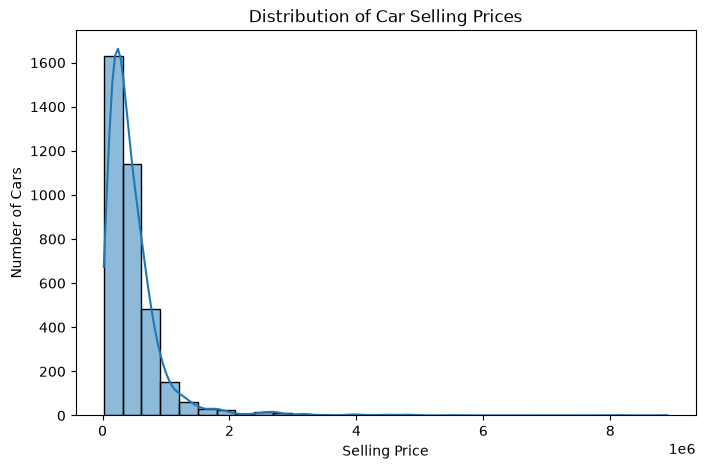

In [39]:
# Plot the distribution of selling prices
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="selling_price", bins=30, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.show()

**Observation:**

The selling price distribution is positively skewed (right-skewed). Most cars have relatively low selling prices, while only a small number of cars have very high selling prices. This creates a long tail towards the right side of the distribution.

### Selling Price vs. Fuel Type

We use a boxplot to compare the selling price distributions of cars with different fuel types.

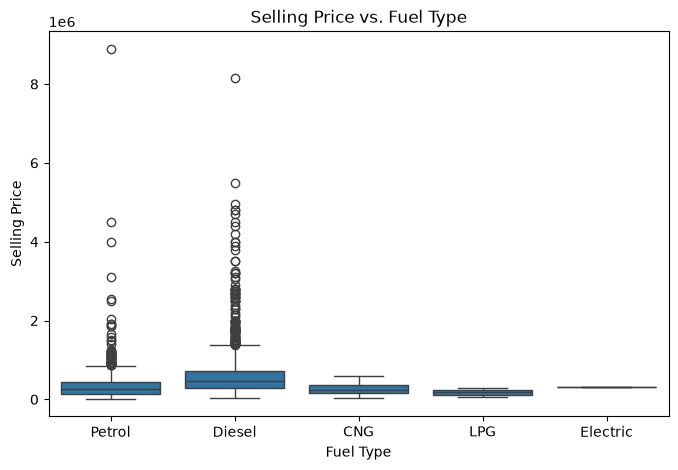

In [40]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="fuel", y="selling_price")

plt.title("Selling Price vs. Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.show()

**Observation:**

The boxplot shows differences in selling prices across fuel types. Diesel cars have a higher median selling price than petrol cars in this dataset. Petrol and diesel categories also contain several high-price outliers. CNG and LPG cars generally have lower selling prices.

### Selling Price vs. Car Age

We use a scatter plot to examine the relationship between car age and selling price. This helps us understand how the age of a car may affect its market value.

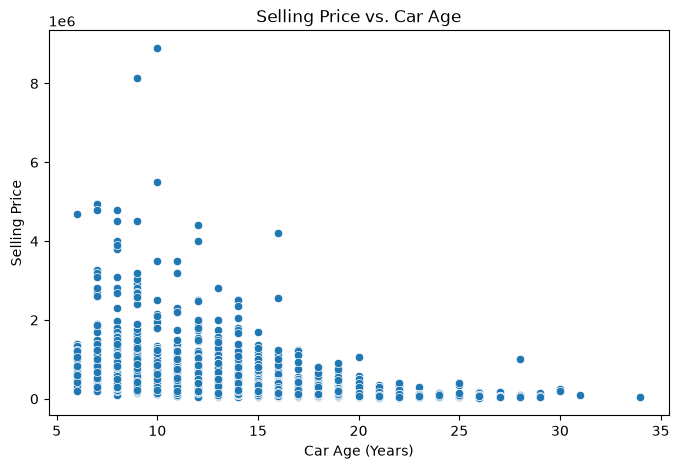

In [41]:
# Plot selling price against car age
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="car_age", y="selling_price")

plt.title("Selling Price vs. Car Age")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.show()

**Observation:**

The scatter plot shows a strong negative relationship between car age and selling price. Generally, newer cars have higher selling prices, while older cars tend to have lower prices. However, considerable variation exists among cars of similar ages, suggesting that other factors, such as brand and model, also influence selling prices. The relationship may be non-linear, indicating that different regression models should be compared during model training.

## 7. Categorical Encoding

Categorical encoding converts text-based categories into numerical values so they can be used by machine learning algorithms.

We use One-Hot Encoding to represent categorical variables numerically.

In [42]:
# Standardise categorical values
for column in categorical_columns:
    df[column] = df[column].str.strip().str.title()

# Check unique values again
for column in categorical_columns:
    print(column, ":", df[column].unique())

fuel : <StringArray>
['Petrol', 'Diesel', 'Cng', 'Lpg', 'Electric']
Length: 5, dtype: str
seller_type : <StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str
transmission : <StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str
owner : <StringArray>
[         'First Owner',         'Second Owner', 'Fourth & Above Owner',
          'Third Owner',       'Test Drive Car']
Length: 5, dtype: str


In [43]:
# Convert categorical columns into numerical values
df_encoded = pd.get_dummies(
    df,
    columns=["fuel", "seller_type", "transmission", "owner", "brand"],
    drop_first=True,
    dtype=int
)

# Display the first five rows
df_encoded.head()

,name,year,selling_price,km_driven,car_age,fuel_Diesel,fuel_Electric,fuel_Lpg,fuel_Petrol,seller_type_Individual,...,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_OpelCorsa,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
0,Maruti 800 AC,2007,60000,70000,19,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
1,Maruti Wagon R LXI Minor,2007,135000,50000,19,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
2,Hyundai Verna 1.6 SX,2012,600000,100000,14,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,Datsun RediGO T Option,2017,250000,46000,9,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
4,Honda Amaze VX i-DTEC,2014,450000,141000,12,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


## 8. Feature Correlation Heatmap

A correlation heatmap shows the strength and direction of relationships between numerical features. It helps us understand which features are associated with the car's selling price.

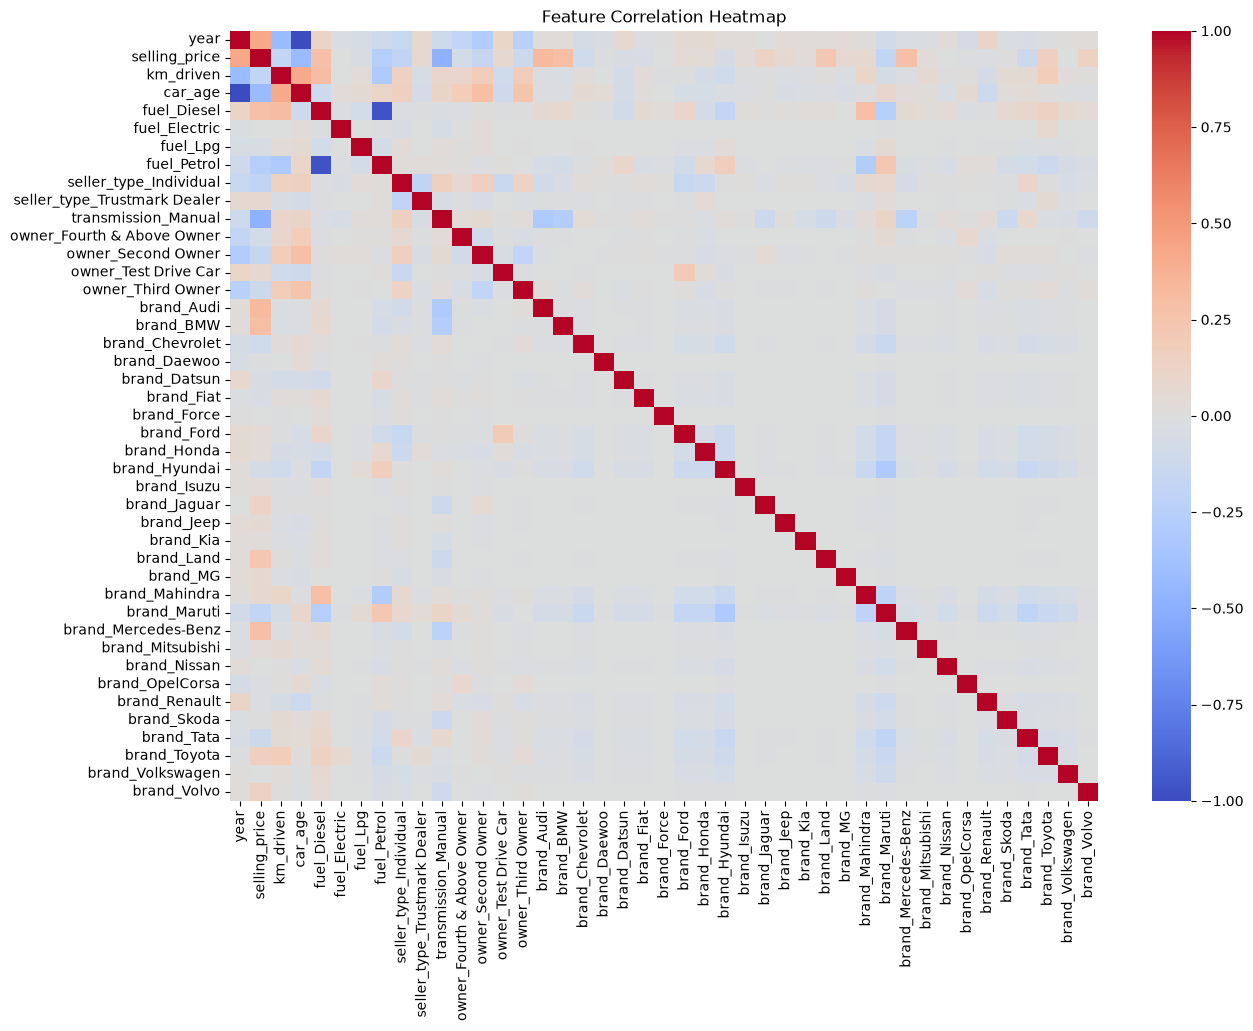

In [44]:
# Calculate correlations between numerical columns
correlation = df_encoded.corr(numeric_only=True)

# Plot the correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(correlation, cmap="coolwarm", annot=False)

plt.title("Feature Correlation Heatmap")
plt.show()

## 9. Model Preparation

Before training machine learning models, we separate the input features from the target variable.

- **Features (X):** Information used to predict the car's price.
- **Target (y):** The selling price we want to predict.

In [45]:
# Select input features
X = df_encoded.drop(columns=["selling_price", "name", "year"])

# Select target variable
y = df_encoded["selling_price"]

# Display the shapes
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3577, 41)
Target shape: (3577,)


### Train-Test Split

We split the dataset into training and testing sets. The training set is used to train the machine learning models, while the testing set evaluates their performance on unseen data.

In [46]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of the datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (2861, 41)
Testing features: (716, 41)
Training target: (2861,)
Testing target: (716,)


## 10. Model Training

We train two regression models: Linear Regression and Random Forest Regressor. Their performance will be compared to identify the better model.

### 10.1 Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values. It learns the relationship between input features, such as car age and kilometres driven, and the selling price.

In this project, we use Linear Regression to predict the selling prices of used cars.

In [47]:
# Create the Linear Regression model
lr_model = LinearRegression()

# Train the model using training data
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


### 10.2 Random Forest Regressor

Random Forest is an ensemble machine learning algorithm that combines multiple decision trees to make predictions. It can capture complex and non-linear relationships between features.

In this project, we use Random Forest to predict car selling prices and compare its performance with Linear Regression.

In [48]:
# Create the Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model using training data
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 11.Model Evaluation
 ### 11.1 Model Predictions

After training the models, we use them to predict the selling prices of cars in the testing dataset. These predictions will be compared with the actual selling prices to evaluate model performance.

In [49]:
# Generate predictions using both models
lr_predictions = lr_model.predict(X_test)

rf_predictions = rf_model.predict(X_test)

# Display the first five predictions
print("Linear Regression predictions:", lr_predictions[:5])
print("Random Forest predictions:", rf_predictions[:5])

Linear Regression predictions: [ 518543.05510381  467970.89946151  963884.25381398 2190416.6599776
  136019.83256751]
Random Forest predictions: [ 568614.04401154  464037.43416667 1441619.908      2459339.98
  238275.        ]


### 11.2 Evaluation Metrics

We evaluate the performance of both regression models using three metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted prices. Lower is better.
- **RMSE (Root Mean Squared Error):** Measures prediction errors while giving greater weight to large errors. Lower is better.
- **R² Score:** Measures how well the model explains variations in selling prices. A value closer to 1 is generally better.

**Linear Regression**

In [50]:
# Evaluate Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))

lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Performance:")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression Performance:
MAE: 185413.7601837149
RMSE: 380273.354725372
R2 Score: 0.5510932901086288


**Random Forest**

In [51]:
# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance:")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Performance:
MAE: 158970.50799542782
RMSE: 368858.975989734
R2 Score: 0.5776378252413277


## 12. Model Comparison

Both Linear Regression and Random Forest Regressor were evaluated using MAE, RMSE, and R² score.

Random Forest achieved a lower MAE and RMSE, along with a higher R² score than Linear Regression.

Therefore, Random Forest is selected as the best-performing model for this dataset based on the test results.

In [52]:
# Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,185413.760184,380273.354725,0.551093
1,Random Forest,158970.507995,368858.975990,0.577638


## 13. Feature Importance Analysis

Feature importance helps us understand which input variables contribute most to the predictions made by the Random Forest model.

We use the feature importance values from the trained Random Forest Regressor to identify the most influential features in predicting car selling prices.

In [53]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 important features
feature_importance.head(10)

,Feature,Importance
8,transmission_Manual,0.244025
1,car_age,0.222521
0,km_driven,0.141477
2,fuel_Diesel,0.063383
13,brand_Audi,0.052567
5,fuel_Petrol,0.050039
27,brand_Land,0.040486
38,brand_Toyota,0.037465
6,seller_type_Individual,0.017896
14,brand_BMW,0.013852


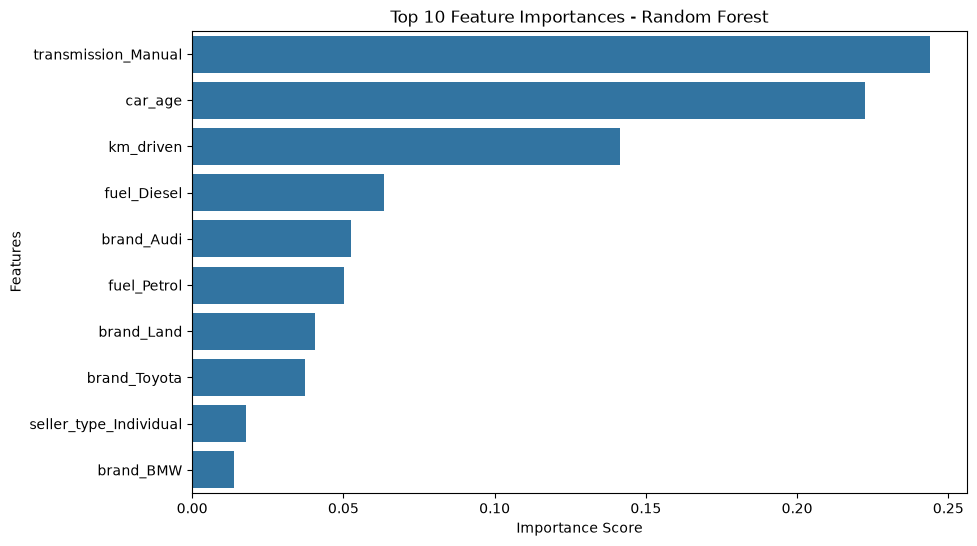

In [54]:
# Plot the top 10 important features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

**Observation:**

The feature importance analysis shows that transmission type, car age, and kilometres driven are the most influential features in predicting car selling prices.

Among these, `transmission_Manual` has the highest importance, followed by `car_age` and `km_driven`. This indicates that vehicle characteristics play an important role in determining selling prices.

# 14. Conclusion

In this project, we developed machine learning models to predict the selling prices of used cars using the CarDekho dataset.

We performed data cleaning, feature engineering, exploratory data analysis, categorical encoding, and feature correlation analysis.

We trained and evaluated two regression models: Linear Regression and Random Forest Regressor.

Based on the evaluation results, Random Forest performed better, achieving:

- **MAE:** 158,970.51
- **RMSE:** 368,858.98
- **R² Score:** 0.5776

The feature importance analysis identified transmission type, car age, and kilometres driven as the most influential features.

Overall, this project demonstrates how machine learning techniques can be used to analyse used-car data and predict selling prices.